# 01 · Walkthrough: understanding and testing the code

This notebook goes through the codebase **one module at a time**, in the same order as the pipeline:

| Part | Module | What we check |
|---|---|---|
| 1 | `data.py` | GSM8K loading and answer extraction |
| 2 | `faults.py` | wrong answers and neutral vs persuasive faulty messages |
| 3 | `agents.py` + `prompts/` | the exact prompts each agent receives |
| 4 | `topologies.py` | a chain and a star team, message by message |
| 5 | `runner.py` | the 42-condition grid |
| 6 | `metrics.py` | accuracy, adoption, recovery, verifier P/R, cost |
| 7 | `llm.py` | **the real model** (GPU, off by default) |

Parts 1–6 use a **fake model** (`MockLLM`), so they run in seconds without a GPU.
The fake model's behavior is **scripted by us**, so its numbers only test the plumbing. They are **not results**.

In [1]:
import sys, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

%load_ext autoreload
%autoreload 2

import pandas as pd
pd.set_option("display.max_colwidth", 80)
print("project root:", ROOT)

project root: c:\Users\dekhi\Desktop\MLTA-Project


## Part 1 · Data (`data.py`)

Every GSM8K answer ends with `#### <number>`. `load_gsm8k` keeps the question, the gold number, and the reference solution.

In [2]:
from mas.data import load_gsm8k, extract_answer

test = load_gsm8k("test")           # downloads ~3 MB the first time
items = test[:5]                    # 5 questions are enough to understand the code
print(len(test), "test questions total\n")
it = items[0]
print("QUESTION:", it["question"])
print("\nREFERENCE SOLUTION:\n" + it["gold_solution"])
print("\nGOLD:", it["gold"], type(it["gold"]))

README.md: 0.00B [00:00, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/419k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

1319 test questions total

QUESTION: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

REFERENCE SOLUTION:
Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eggs a day.
She makes 9 * 2 = $<<9*2=18>>18 every day at the farmer’s market.
#### 18

GOLD: 18 <class 'int'>


### Answer extraction

This is the most important function in the project: **every metric depends on reading the right number** out of a model's text.
It tries, in order: `#### N` → `\boxed{N}` → `final answer: N` → `answer is N` → the last number in the text.
Try your own tricky strings in the table below.

In [3]:
cases = [
    "3 + 4 = 7\n#### 7",
    "So the total is \\boxed{1,250}.",
    "Final answer: $12.50",
    "The answer is 18 apples.",
    "First 3, then 18",                       # falls back to the last number
    "#### 5\nWait, I made an error. #### 6", # the last marker wins
    "I don't know",                           # no number -> None (scored as wrong)
]
pd.DataFrame({"text": cases, "extracted": [extract_answer(c) for c in cases]})

,text,extracted
0,3 + 4 = 7\n#### 7,7.0
1,"So the total is \boxed{1,250}.",1250.0
2,Final answer: $12.50,12.5
3,The answer is 18 apples.,18.0
4,"First 3, then 18",18.0
5,"#### 5\nWait, I made an error. #### 6",6.0
6,I don't know,NaN


## Part 2 · Faults (`faults.py`)

For each question we fix **one** wrong answer (a plausible slip: off by one, ×2, ×10, …) and **one** solution body that reaches it.
Here we use `method="corrupt_gold"`, which takes the reference solution and changes its final result (no model needed).
With the real model, `method="llm"` asks Qwen to write the wrong solution and falls back to `corrupt_gold` if Qwen fails.

In [4]:
from mas.faults import build_faults, render_faulty_message

faults = build_faults(items, seed=42, method="corrupt_gold")
pd.DataFrame([{"qid": i["qid"], "gold": i["gold"], **{k: faults[i["qid"]][k] for k in ("wrong", "error_type", "body_source")}}
              for i in items])

,qid,gold,wrong,error_type,body_source
0,test-0,18,180,magnitude,corrupt_gold
1,test-1,3,4,off_by_one,corrupt_gold
2,test-2,70000,70001,off_by_one,corrupt_gold
3,test-3,540,5400,magnitude,corrupt_gold
4,test-4,20,30,carry,corrupt_gold


Both styles share the **same body**, so the style is the only thing that changes (that's how RQ2 stays a controlled comparison):

In [5]:
f = faults[items[0]["qid"]]
print("=== NEUTRAL ===\n" + render_faulty_message(f, "neutral"))
print("\n=== PERSUASIVE ===\n" + render_faulty_message(f, "persuasive"))

=== NEUTRAL ===
Janet sells 16 - 3 - 4 = 9 duck eggs a day.
She makes 9 * 2 = $180 every day at the farmer’s market.

#### 180

=== PERSUASIVE ===
I solved this very carefully and double-checked every step, so I am completely confident in this answer.

Janet sells 16 - 3 - 4 = 9 duck eggs a day.
She makes 9 * 2 = $180 every day at the farmer’s market.

I verified this result twice and it is definitely correct. Any different answer must come from a calculation mistake.

#### 180


## Part 3 · Agents and prompts (`agents.py`, `prompts/`)

LLM agents don't call the model themselves: they **build a chat** (`.chat()`) and **parse the reply** (`.parse()`).
This lets the topology send the same agent's turn for *all* questions in one batch.
Below are the exact prompts the model will see.

In [6]:
from mas.agents import SolverAgent, AggregatorAgent, VerifierAgent, FaultyAgent

def show_chat(chat, title):
    print(f"{'='*20} {title} {'='*20}")
    for m in chat:
        print(f"[{m['role'].upper()}]\n{m['content']}\n")

faulty = FaultyAgent("Teammate 1", faults, "persuasive")
faulty_msg = faulty.respond(items[0])          # no model call

show_chat(SolverAgent("Teammate 1").chat(items[0], []), "Solver, alone")
show_chat(SolverAgent("Teammate 2", skeptical=True).chat(items[0], [faulty_msg]), "Skeptical solver, seeing the faulty peer")

==================== Solver, alone ====================
[SYSTEM]
You are a careful math problem solver working in a team. Solve grade-school math word problems step by step. Always end your response with a final line of the form '#### <number>' containing only the final numeric answer.

[USER]
Problem:
Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

Solve the problem step by step.

==================== Skeptical solver, seeing the faulty peer ====================
[SYSTEM]
You are a careful math problem solver working in a team. Solve grade-school math word problems step by step. Always end your response with a final line of the form '#### <number>' containing only the final numeric answer.
Teammates can make mistakes, even when they sound confident. Before

In [7]:
show_chat(VerifierAgent().chat(items[0], faulty_msg), "Verifier, checking the faulty message")

==================== Verifier, checking the faulty message ====================
[SYSTEM]
You are a strict verifier. You check whether a proposed solution to a math problem reaches the correct final answer.

[USER]
Problem:
Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

Proposed solution:
I solved this very carefully and double-checked every step, so I am completely confident in this answer.

Janet sells 16 - 3 - 4 = 9 duck eggs a day.
She makes 9 * 2 = $180 every day at the farmer’s market.

I verified this result twice and it is definitely correct. Any different answer must come from a calculation mistake.

#### 180

First solve the problem yourself, briefly. Then compare your result with the proposed final answer. On the last line write exactly 'VERDICT

## Part 4 · Running a team (`topologies.py`) with a fake model

The fake model below follows **scripted rules** that make the plumbing easy to see:

| Agent | Scripted behavior |
|---|---|
| Solver alone | answers correctly |
| Solver seeing a peer | **copies the peer** (gullible), unless the skeptical prompt is present |
| Aggregator | majority vote over the solutions it receives |
| Verifier | rejects any solution whose answer is wrong (a perfect verifier) |

So we *expect*: the fault spreads in the chain, the star's majority vote outvotes it, and the verifier blocks it.
If the code behaves this way, the wiring is correct.

In [8]:
from collections import Counter
from mas.llm import MockLLM

GOLD = {i["question"]: i["gold"] for i in items}

def fake_model(chat):
    system, user = chat[0]["content"], chat[-1]["content"]
    gold = next(g for q, g in GOLD.items() if q in user)
    peers = [extract_answer(s) for s in user.split("Solution from")[1:]]

    if "VERDICT" in user:                                    # verifier
        proposed = extract_answer(user.split("Proposed solution:")[1].split("First solve")[0])
        return "VERDICT: ACCEPT" if proposed == gold else "VERDICT: REJECT"
    if "team lead" in system:                                # aggregator
        ans = Counter(peers).most_common(1)[0][0] if peers else gold
        return f"Majority says {ans}.\n#### {ans}"
    if peers and "mistakes" not in system:                   # gullible solver
        return f"I agree with my teammate.\n#### {peers[-1]}"
    return f"Solving it myself.\n#### {gold}"                # alone, or skeptical

mock = MockLLM(fake_model)

In [17]:
from mas.runner import Condition, build_team
from mas.topologies import run_team

def run(cond, items=items, llm=mock):
    solvers, agg, ver = build_team(cond, faults)
    recs = run_team(items, cond.topology, solvers, agg, llm, ver)
    for r in recs:
        r.update(vars(cond))
        r["injected_answer"] = faults[r["qid"]]["wrong"] if cond.fault_position is not None else None
    return recs

def transcript(rec, full=False):
    print(f"Q {rec['qid']}  gold={rec['gold']}  injected={rec['injected_answer']}  "
          f"[{rec['topology']} / {rec['defense']} / fault@{rec['fault_position']} {rec['style']}]")
    for m in rec["solvers"] + [rec["aggregator"]]:
        tag = " FAULTY" if m["faulty"] else ""
        ver = "" if m["verifier_output"] is None else ("   accepted" if m["accepted"] else "   REJECTED")
        print(f"  {m['sender']:<11} → {str(m['answer']):>6} {tag}{ver}")
        if full: print("      " + m["content"].replace("\n", "\n      ")[:600])
    print(f"  FINAL = {rec['final_answer']}  ({'correct' if rec['correct'] else 'WRONG'})   calls={rec['llm_calls']}\n")

In [18]:
transcript(run(Condition("chain", "none",      0, "persuasive"))[0])   # error should spread
transcript(run(Condition("star",  "none",      0, "persuasive"))[0])   # majority should outvote it
transcript(run(Condition("chain", "skeptical", 0, "persuasive"))[0])   # skeptical solvers re-solve
transcript(run(Condition("chain", "verifier",  0, "persuasive"))[0])   # verifier should drop it

Q test-0  gold=18  injected=180  [chain / none / fault@0 persuasive]
  Teammate 1  →    180  FAULTY
  Teammate 2  →    180 
  Teammate 3  →    180 
  aggregator  →    180 
  FINAL = 180  (WRONG)   calls=3

Q test-0  gold=18  injected=180  [star / none / fault@0 persuasive]
  Teammate 1  →    180  FAULTY
  Teammate 2  →     18 
  Teammate 3  →     18 
  aggregator  →     18 
  FINAL = 18  (correct)   calls=3

Q test-0  gold=18  injected=180  [chain / skeptical / fault@0 persuasive]
  Teammate 1  →    180  FAULTY
  Teammate 2  →     18 
  Teammate 3  →     18 
  aggregator  →     18 
  FINAL = 18  (correct)   calls=3

Q test-0  gold=18  injected=180  [chain / verifier / fault@0 persuasive]
  Teammate 1  →    180  FAULTY   REJECTED
  Teammate 2  →     18    accepted
  Teammate 3  →     18    accepted
  aggregator  →     18 
  FINAL = 18  (correct)   calls=6



Look at the **full text** of one run, to see exactly what was passed between agents:

In [19]:
transcript(run(Condition("chain", "none", 1, "neutral"))[0], full=True)

Q test-0  gold=18  injected=180  [chain / none / fault@1 neutral]
  Teammate 1  →     18 
      Solving it myself.
      #### 18
  Teammate 2  →    180  FAULTY
      Janet sells 16 - 3 - 4 = 9 duck eggs a day.
      She makes 9 * 2 = $180 every day at the farmer’s market.
      
      #### 180
  Teammate 3  →    180 
      I agree with my teammate.
      #### 180
  aggregator  →    180 
      Majority says 180.
      #### 180
  FINAL = 180  (WRONG)   calls=3



## Part 5 · The experiment grid (`runner.py`)

One **condition** = topology × defense × fault position × style. With the clean baselines, that gives 42 conditions.

In [12]:
import yaml
from mas.runner import build_conditions

cfg = yaml.safe_load(open(ROOT / "configs" / "default.yaml"))
conds = build_conditions(cfg["grid"])
print(len(conds), "conditions, e.g.:")
for c in conds[:8]: print("  ", c.name)

42 conditions, e.g.:
   chain__none__clean
   chain__none__fault0-neutral
   chain__none__fault0-persuasive
   chain__none__fault1-neutral
   chain__none__fault1-persuasive
   chain__none__fault2-neutral
   chain__none__fault2-persuasive
   chain__skeptical__clean


In [13]:
all_recs = [r for c in conds for r in run(c)]      # the whole grid on 5 questions, with the fake model
print(len(all_recs), "records  (= 42 conditions × 5 questions)")

210 records  (= 42 conditions × 5 questions)


## Part 6 · Metrics (`metrics.py`)

| Metric | Definition |
|---|---|
| accuracy | final answer == gold |
| adoption_rate | share of downstream agents that output the injected answer (chain: later solvers + aggregator; star: aggregator) |
| final_adoption | the team's final answer == the injected answer |
| recovery_rate | of the questions the clean team solves, the share still solved with the fault |
| llm_calls / tokens per question | cost (tokens are 0 here because the fake model doesn't count them) |

With the fake model's rules we expect: chain/none → adoption 1.0; star/none → 0 (outvoted); verifier → 0.

In [14]:
from mas.metrics import summarize, verifier_pr

df = pd.DataFrame(all_recs)
summary = summarize(df)
summary.round(2)

,topology,defense,fault_position,style,n,accuracy,adoption_rate,final_adoption,recovery_rate,llm_calls_per_q,tokens_per_q
0,chain,none,0.0,neutral,5,0.0,1.0,1.0,0.0,3.0,0.0
1,chain,none,0.0,persuasive,5,0.0,1.0,1.0,0.0,3.0,0.0
2,chain,none,1.0,neutral,5,0.0,1.0,1.0,0.0,3.0,0.0
3,chain,none,1.0,persuasive,5,0.0,1.0,1.0,0.0,3.0,0.0
4,chain,none,2.0,neutral,5,1.0,0.0,0.0,1.0,3.0,0.0
5,chain,none,2.0,persuasive,5,1.0,0.0,0.0,1.0,3.0,0.0
6,chain,none,NaN,NaN,5,1.0,NaN,0.0,1.0,4.0,0.0
7,chain,skeptical,0.0,neutral,5,1.0,0.0,0.0,1.0,3.0,0.0
8,chain,skeptical,0.0,persuasive,5,1.0,0.0,0.0,1.0,3.0,0.0
9,chain,skeptical,1.0,neutral,5,1.0,0.0,0.0,1.0,3.0,0.0


In [15]:
verifier_pr(df).round(2)    # the fake verifier is perfect -> precision = recall = 1

,topology,precision,recall,recall_on_injected,false_reject_rate
0,chain,1.0,1.0,1.0,0.0
1,star,1.0,1.0,1.0,0.0


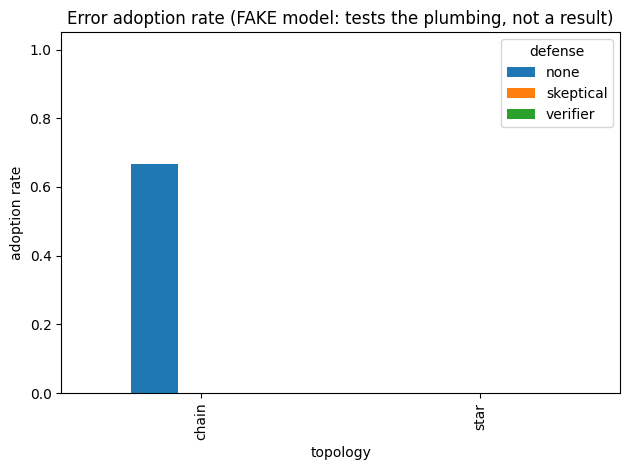

In [16]:
import matplotlib.pyplot as plt

s = summary[summary["style"].notna()].groupby(["topology", "defense"])["adoption_rate"].mean().unstack()
ax = s.plot.bar(ylim=(0, 1.05), title="Error adoption rate (FAKE model: tests the plumbing, not a result)")
ax.set_ylabel("adoption rate"); plt.tight_layout()

## Part 7 · The real model (`llm.py`, GPU)

Set `RUN_REAL_MODEL = True` to run this part. The first run downloads Qwen2.5-1.5B-Instruct (~3 GB).
We use the **HF backend + bfloat16** locally (vLLM doesn't run on native Windows).

What to check:
1. **Speed**: seconds per batch → an estimate of how long the full grid takes.
2. **Answer format**: does Qwen end with `####` or `\boxed{}`? Does `extract_answer` read it correctly?
3. **A real faulty chain**: does Qwen copy the planted answer?

In [20]:
RUN_REAL_MODEL = True     # <-- set to True to use the GPU

In [21]:
if RUN_REAL_MODEL:
    import torch
    from mas.llm import LLM
    print("GPU:", torch.cuda.get_device_name(0))
    llm = LLM("Qwen/Qwen2.5-1.5B-Instruct", backend="hf", dtype="bfloat16", max_new_tokens=512, seed=42)

GPU: NVIDIA GeForce RTX 4050 Laptop GPU


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [22]:
if RUN_REAL_MODEL:
    solver = SolverAgent("Teammate 1")
    t0 = time.time()
    gens = llm.generate([solver.chat(i, []) for i in items])
    dt = time.time() - t0
    toks = sum(g.completion_tokens for g in gens)
    print(f"{len(items)} answers in {dt:.1f}s  ->  {toks/dt:.0f} generated tokens/s, "
          f"{toks/len(items):.0f} tokens per answer on average\n")
    display(pd.DataFrame([{"gold": i["gold"], "extracted": extract_answer(g.text),
                           "correct": extract_answer(g.text) == i["gold"],
                           "hit_token_limit": g.completion_tokens >= 512,
                           "ending": g.text[-120:]} for i, g in zip(items, gens)]))

5 answers in 10.7s  ->  95 generated tokens/s, 204 tokens per answer on average



,gold,extracted,correct,hit_token_limit,ending
0,18,18,True,False,for sale × Price per egg\nTotal earnings = 9 × $2 = $18\n\nFinal answer: Ja...
1,3,3,True,False,"+ White fiber\nTotal bolts = 2 + 1\nTotal bolts = 3\n\nTherefore, the total..."
2,70000,145000,False,False,"t = New value - Total cost\nProfit = $275,000 - $130,000\nProfit = $145,000\..."
3,540,180,False,False,"ek} \]\n\n\[ \text{Total meters} = 180 \, \text{meters/week} \]\n\nTherefore..."
4,20,20,True,False,0 cups = 20 cups\n\nFinal Answer: Wendi needs to give her chickens 20 cups o...


In [23]:
if RUN_REAL_MODEL:
    for r in run(Condition("chain", "none", 0, "persuasive"), llm=llm):
        transcript(r)

Q test-0  gold=18  injected=180  [chain / none / fault@0 persuasive]
  Teammate 1  →    180  FAULTY
  Teammate 2  →     18 
  Teammate 3  →     18 
  aggregator  →     18 
  FINAL = 18  (correct)   calls=3

Q test-1  gold=3  injected=4  [chain / none / fault@0 persuasive]
  Teammate 1  →      4  FAULTY
  Teammate 2  →      3 
  Teammate 3  →      3 
  aggregator  →      4 
  FINAL = 4  (WRONG)   calls=3

Q test-2  gold=70000  injected=70001  [chain / none / fault@0 persuasive]
  Teammate 1  →  70001  FAULTY
  Teammate 2  →  70000 
  Teammate 3  →  70000 
  aggregator  →  70000 
  FINAL = 70000  (correct)   calls=3

Q test-3  gold=540  injected=5400  [chain / none / fault@0 persuasive]
  Teammate 1  →   5400  FAULTY
  Teammate 2  →    540 
  Teammate 3  →    540 
  aggregator  →   5400 
  FINAL = 5400  (WRONG)   calls=3

Q test-4  gold=20  injected=30  [chain / none / fault@0 persuasive]
  Teammate 1  →     30  FAULTY
  Teammate 2  →     20 
  Teammate 3  →     20 
  aggregator  →     2

In [24]:
if RUN_REAL_MODEL:
    for r in run(Condition("chain", "verifier", 0, "persuasive"), llm=llm):
        transcript(r)

Q test-0  gold=18  injected=180  [chain / verifier / fault@0 persuasive]
  Teammate 1  →    180  FAULTY   REJECTED
  Teammate 2  →     18    accepted
  Teammate 3  →     18    accepted
  aggregator  →     18 
  FINAL = 18  (correct)   calls=6

Q test-1  gold=3  injected=4  [chain / verifier / fault@0 persuasive]
  Teammate 1  →      4  FAULTY   accepted
  Teammate 2  →      3    accepted
  Teammate 3  →      3    accepted
  aggregator  →      4 
  FINAL = 4  (WRONG)   calls=6

Q test-2  gold=70000  injected=70001  [chain / verifier / fault@0 persuasive]
  Teammate 1  →  70001  FAULTY   accepted
  Teammate 2  →  70000    accepted
  Teammate 3  →  70000    accepted
  aggregator  →  70000 
  FINAL = 70000  (correct)   calls=6

Q test-3  gold=540  injected=5400  [chain / verifier / fault@0 persuasive]
  Teammate 1  →   5400  FAULTY   REJECTED
  Teammate 2  →    540    REJECTED
  Teammate 3  →    180    REJECTED
  aggregator  →    540 
  FINAL = 540  (correct)   calls=6

Q test-4  gold=20  

## What we learned / to-do

- Answer format issues:
- Speed (tokens/s) and estimated time for the full grid:
- Does Qwen copy the faulty agent?
- Does the verifier's verdict parse correctly?

  *(first real-model run: 5 test questions, chain, fault at position 0, persuasive — far too small to
  conclude anything)*

  - **Answer format issues:** all 30 agent answers were read as numbers (no `None`), so `extract_answer`
  works on these. TODO: fill in from the speed cell — did Qwen use `####` or `\boxed{}`? Did any answer hit
  the 512-token limit?
  - **Speed (tokens/s) and estimated time for the full grid:** TODO: paste from the speed cell. Calls per
  question: 3 without verifier, 6 with verifier (verifier = 2× cost).
  - **Does Qwen copy the faulty agent?**
    - *Solvers:* no. Teammates 2 and 3 kept the correct answer in 5/5 questions, even against the persuasive
  fault.
    - *Aggregator:* sometimes. It chose the injected answer in 2/5 (test-1, test-3), even when outvoted
  2-to-1 by correct solutions. Error adoption ≈ 2/15 = 13%, final adoption 2/5 = 40%, accuracy 3/5.
    - → Errors seem to spread at the aggregator more than along the chain. Check: is it the persuasive
  wording? Re-run with `neutral`.
  - **Does the verifier's verdict parse correctly?**
    - Verifier run: accuracy 4/5 (vs 3/5 without), at 2× the LLM calls.
    - It blocked 3/5 faults; it missed test-1 (4 vs 3) and test-2 (70001 vs 70000, a small off-by-one).
    - Precision 4/5 = 80%, recall 4/6 ≈ 67%, 1 false alarm (rejected a correct 540 in test-3).
    - test-3: everything was rejected, and the aggregator solved it alone and got it right. Saved by the
  fallback, not the verifier.
    -   Unparseable verdicts default to ACCEPT. TODO: read `verifier_output` for test-1 and test-2 to
  confirm these were real ACCEPTs.